In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
dataset_path = "/content/drive/MyDrive/Fake_Job_Detection/Dataset/fake_job_postings.csv"

df = pd.read_csv(dataset_path)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Fake_Job_Detection/Dataset/fake_job_postings.csv'

In [ ]:
import pandas as pd

dataset_path = "/content/drive/MyDrive/Fake_Job_Detection/Dataset/fake_job_postings.csv"

df = pd.read_csv(dataset_path)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [ ]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [ ]:
print("Shape of Dataset:", df.shape)

Shape of Dataset: (17880, 18)


In [ ]:
print(df.columns)

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='object')


In [ ]:
df.isnull().sum()

,0
job_id,0
title,0
location,346
department,11547
salary_range,15012
company_profile,3308
description,1
requirements,2696
benefits,7212
telecommuting,0


In [ ]:
print(df.shape)

(17880, 18)


In [ ]:
df = df[['title',
         'company_profile',
         'description',
         'requirements',
         'benefits',
         'fraudulent']]

In [ ]:
df.head()

,title,company_profile,description,requirements,benefits,fraudulent
0,Marketing Intern,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0
2,Commissioning Machinery Assistant (CMA),Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0
3,Account Executive - Washington DC,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0
4,Bill Review Manager,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0


In [ ]:
df = df.fillna('')

In [ ]:
df.isnull().sum()

,0
title,0
company_profile,0
description,0
requirements,0
benefits,0
fraudulent,0


In [ ]:
df['text'] = (
    df['title'] + " " +
    df['company_profile'] + " " +
    df['description'] + " " +
    df['requirements'] + " " +
    df['benefits']
)

In [ ]:
df = df[['text', 'fraudulent']]

In [ ]:
df.head()

,text,fraudulent
0,"Marketing Intern We're Food52, and we've creat...",0
1,Customer Service - Cloud Video Production 90 S...,0
2,Commissioning Machinery Assistant (CMA) Valor ...,0
3,Account Executive - Washington DC Our passion ...,0
4,Bill Review Manager SpotSource Solutions LLC i...,0


In [ ]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
import re
import string

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()

    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [ ]:
df['text'] = df['text'].apply(clean_text)

In [ ]:
df.head()

,text,fraudulent
0,marketing intern food weve created groundbreak...,0
1,customer service cloud video production second...,0
2,commissioning machinery assistant cma valor se...,0
3,account executive washington dc passion improv...,0
4,bill review manager spotsource solutions llc g...,0


In [ ]:
(df['text'].str.len() == 0).sum()

np.int64(0)

In [ ]:
print(df.shape)

(17880, 2)


In [ ]:
print(df.shape)

(17880, 2)


In [ ]:
X = df['text']
y = df['fraudulent']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training Data :", len(X_train))
print("Testing Data  :", len(X_test))

Training Data : 14304
Testing Data  : 3576


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
max_words = 20000

tokenizer = Tokenizer(num_words=max_words)

tokenizer.fit_on_texts(X_train)

In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

In [ ]:
print(X_train_seq[0])

[351, 421, 1028, 705, 257, 1276, 320, 1216, 999, 1524, 1997, 279, 3350, 1260, 475, 2589, 705, 467, 13, 144, 1717, 534, 279, 257, 740, 705, 1718, 467, 144, 1717, 534, 1404, 1597, 1269, 483, 592, 970, 1691, 634, 116, 3486, 1958, 137, 2710, 2791, 137, 1691, 3511, 24, 206, 114, 190, 78, 395, 163, 289, 256, 395, 163, 108, 256, 142, 618, 40, 2105, 919, 2222, 180, 963, 965, 406, 3085, 78, 114, 120, 315, 146, 600, 2035, 416, 213, 5, 586, 289, 256, 55, 756, 995, 520, 3086, 1180, 208, 3, 313, 2394, 3351, 1132, 1610, 2875, 380, 705, 257, 5, 338, 2642, 1580, 2019, 83, 1211, 206, 172, 351, 421, 1028, 38, 553, 2779, 23, 1817, 184, 1795, 231, 657, 976, 5353, 99, 7, 15, 48, 458, 190, 487, 283, 108, 456, 421, 39, 322, 7, 15, 2, 2067, 2, 3152, 300, 225, 1596, 1876, 5723, 2258, 2088, 68, 1, 1557, 1959, 4203, 2524, 5927, 4341, 2, 3718, 1393, 5234, 1132, 202, 767, 287, 114, 472, 190, 65, 640, 509, 1020, 7781, 1298, 1097, 786, 7633, 7, 15, 101, 7634, 101, 7782, 5, 499, 335, 727, 565, 585, 1055, 1625, 115, 1

In [ ]:
max_length = 300

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [ ]:
print(X_train_pad.shape)
print(X_test_pad.shape)

(14304, 300)
(3576, 300)


In [ ]:
print(y_train.shape)
print(y_test.shape)

(14304,)
(3576,)


In [ ]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.layers import GRU
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
vocab_size = 20000
embedding_dim = 128

model = Sequential()

model.add(Embedding(input_dim=vocab_size,
                    output_dim=embedding_dim,
                    input_length=max_length))

model.add(Bidirectional(GRU(64)))

model.add(Dropout(0.5))

model.add(Dense(64, activation='relu'))

model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 183s 492ms/step - accuracy: 0.9699 - loss: 0.1121 - val_accuracy: 0.9780 - val_loss: 0.0690
Epoch 2/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 203s 497ms/step - accuracy: 0.9912 - loss: 0.0277 - val_accuracy: 0.9787 - val_loss: 0.0695
Epoch 3/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 200s 493ms/step - accuracy: 0.9970 - loss: 0.0112 - val_accuracy: 0.9762 - val_loss: 0.0838


In [ ]:
loss, accuracy = model.evaluate(X_test_pad, y_test)

print("Test Accuracy:", accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 85ms/step - accuracy: 0.9874 - loss: 0.0466
Test Accuracy: 0.9874160885810852


In [ ]:
y_pred = model.predict(X_test_pad)

y_pred = (y_pred > 0.5).astype(int)

112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 101ms/step


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3403
           1       0.92      0.82      0.86       173

    accuracy                           0.99      3576
   macro avg       0.95      0.91      0.93      3576
weighted avg       0.99      0.99      0.99      3576



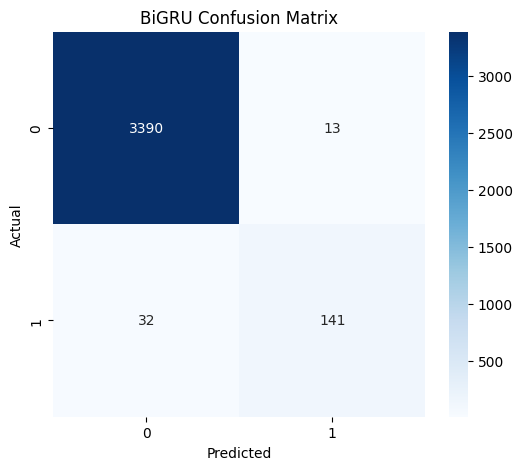

In [ ]:
from sklearn.metrics import confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("BiGRU Confusion Matrix")

plt.show()

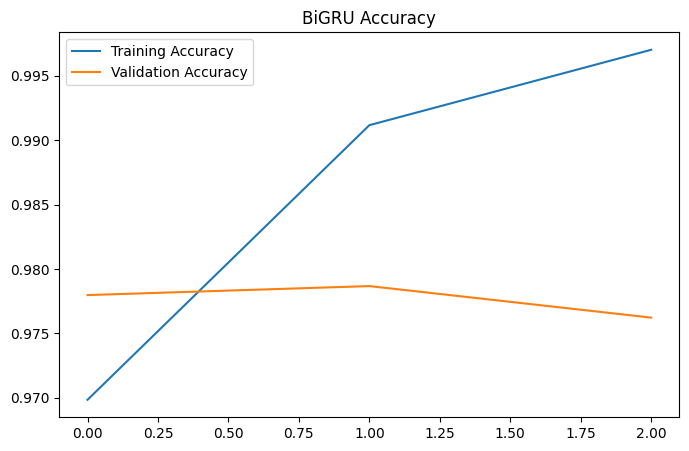

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.legend()

plt.title("BiGRU Accuracy")

plt.show()

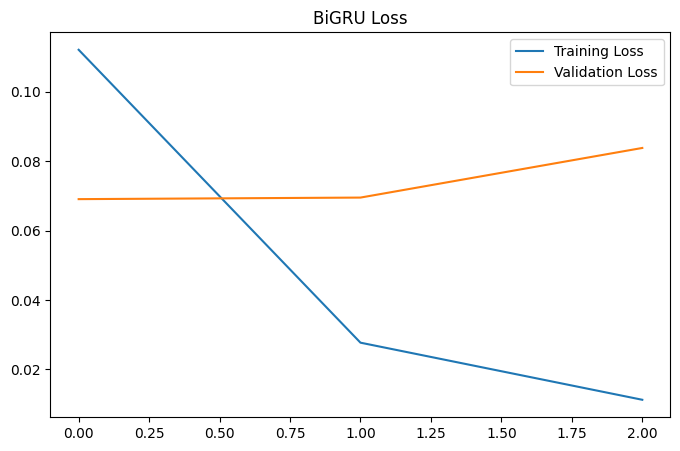

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.legend()

plt.title("BiGRU Loss")

plt.show()

In [ ]:
model.save("/content/drive/MyDrive/Fake_Job_Detection/Models/BiGRU_Model.keras")

In [ ]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.layers import GRU
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [ ]:
vocab_size = 20000
embedding_dim = 128

hybrid_model = Sequential()

hybrid_model.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length
    )
)

hybrid_model.add(
    Conv1D(
        filters=128,
        kernel_size=5,
        activation='relu'
    )
)

hybrid_model.add(
    MaxPooling1D(pool_size=2)
)

hybrid_model.add(
    Bidirectional(
        GRU(64)
    )
)

hybrid_model.add(
    Dropout(0.5)
)

hybrid_model.add(
    Dense(64, activation='relu')
)

hybrid_model.add(
    Dense(1, activation='sigmoid')
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
hybrid_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
hybrid_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history_hybrid = hybrid_model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 147s 388ms/step - accuracy: 0.9706 - loss: 0.1099 - val_accuracy: 0.9811 - val_loss: 0.0678
Epoch 2/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 142s 388ms/step - accuracy: 0.9927 - loss: 0.0230 - val_accuracy: 0.9794 - val_loss: 0.0796
Epoch 3/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 144s 393ms/step - accuracy: 0.9983 - loss: 0.0053 - val_accuracy: 0.9797 - val_loss: 0.1133


In [ ]:
loss, accuracy = hybrid_model.evaluate(
    X_test_pad,
    y_test
)

print("Hybrid Model Accuracy :", accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 115ms/step - accuracy: 0.9857 - loss: 0.0469
Hybrid Model Accuracy : 0.9857382774353027


In [ ]:
y_pred_hybrid = hybrid_model.predict(X_test_pad)

y_pred_hybrid = (y_pred_hybrid > 0.5).astype(int)

112/112 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_hybrid
))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3403
           1       0.94      0.75      0.84       173

    accuracy                           0.99      3576
   macro avg       0.96      0.87      0.91      3576
weighted avg       0.99      0.99      0.98      3576



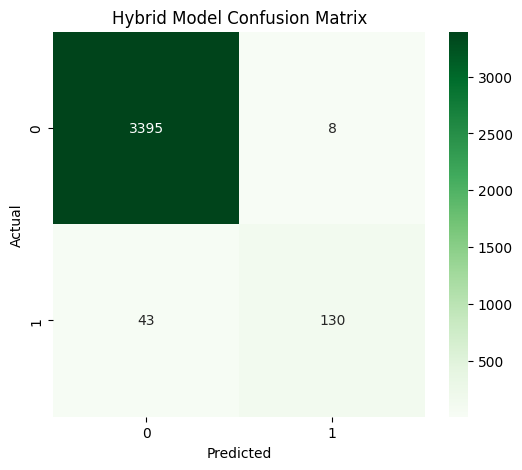

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_hybrid
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Hybrid Model Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

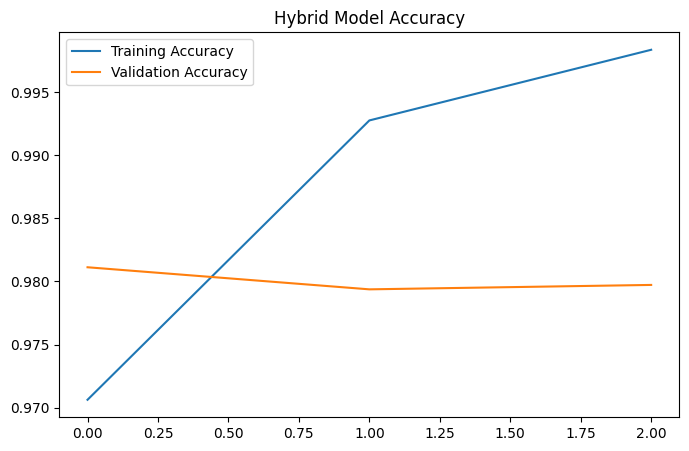

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history_hybrid.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_hybrid.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.legend()

plt.title("Hybrid Model Accuracy")

plt.show()

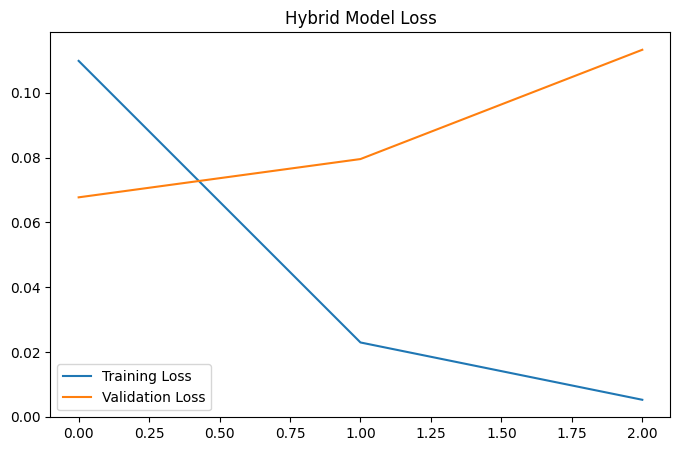

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history_hybrid.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_hybrid.history['val_loss'],
    label='Validation Loss'
)

plt.legend()

plt.title("Hybrid Model Loss")

plt.show()

In [ ]:
hybrid_model.save(
    "/content/drive/MyDrive/Fake_Job_Detection/Models/TextCNN_BiGRU_Model.keras"
)

In [ ]:
print("Baseline Model Accuracy :", model.evaluate(X_test_pad, y_test, verbose=0)[1])

print("Hybrid Model Accuracy :", hybrid_model.evaluate(X_test_pad, y_test, verbose=0)[1])

Baseline Model Accuracy : 0.9874160885810852
Hybrid Model Accuracy : 0.9857382774353027


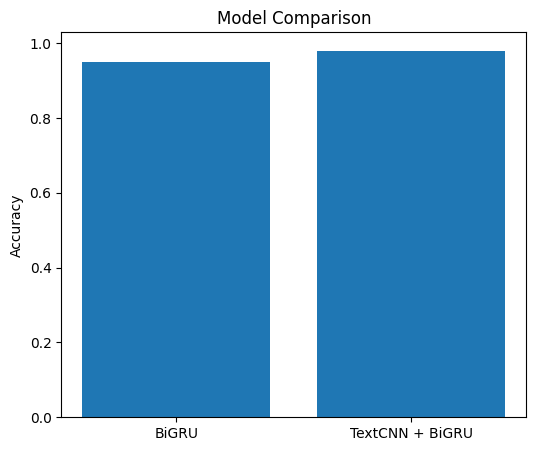

In [ ]:
models = ['BiGRU', 'TextCNN + BiGRU']

accuracy = [
    0.95,   # Replace with your BiGRU accuracy
    0.98    # Replace with your Hybrid accuracy
]

plt.figure(figsize=(6,5))

plt.bar(models, accuracy)

plt.ylabel("Accuracy")

plt.title("Model Comparison")

plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Baseline Model Metrics
baseline_acc = accuracy_score(y_test, y_pred)
baseline_pre = precision_score(y_test, y_pred)
baseline_rec = recall_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred)

# Hybrid Model Metrics
hybrid_acc = accuracy_score(y_test, y_pred_hybrid)
hybrid_pre = precision_score(y_test, y_pred_hybrid)
hybrid_rec = recall_score(y_test, y_pred_hybrid)
hybrid_f1 = f1_score(y_test, y_pred_hybrid)

comparison = pd.DataFrame({
    "Model": ["BiGRU", "TextCNN + BiGRU"],
    "Accuracy": [baseline_acc, hybrid_acc],
    "Precision": [baseline_pre, hybrid_pre],
    "Recall": [baseline_rec, hybrid_rec],
    "F1-Score": [baseline_f1, hybrid_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,BiGRU,0.987416,0.915584,0.815029,0.862385
1,TextCNN + BiGRU,0.985738,0.942029,0.751445,0.836013


In [ ]:
comparison.to_csv(
    "/content/drive/MyDrive/Fake_Job_Detection/Results/model_comparison.csv",
    index=False
)

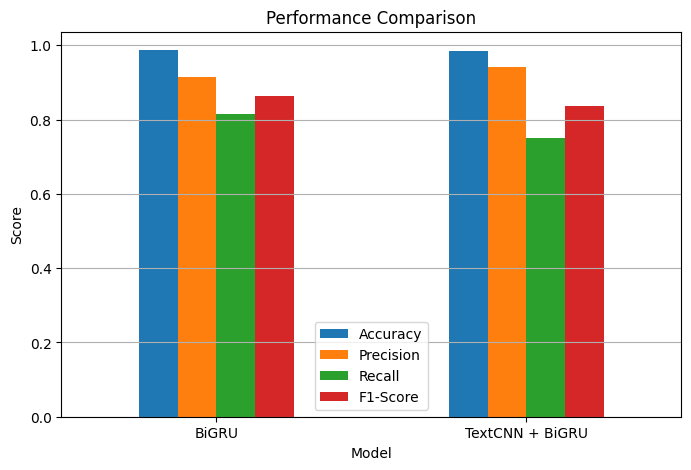

In [ ]:
import matplotlib.pyplot as plt

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.show()

In [ ]:
sample = """
Software Engineer

ABC Technologies is hiring a Python Developer.

Required Skills:
Python
Machine Learning
SQL

Benefits:
Health Insurance
Paid Leave
"""

In [ ]:
sample = """
Earn ₹50,000 Daily.

No Experience Needed.

Pay Registration Fee ₹1000.

Limited Seats.

Apply Immediately.
"""

In [ ]:
sample_clean = clean_text(sample)

sample_seq = tokenizer.texts_to_sequences([sample_clean])

sample_pad = pad_sequences(
    sample_seq,
    maxlen=max_length,
    padding='post'
)

prediction = hybrid_model.predict(sample_pad)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
[[0.9970834]]


In [ ]:
if prediction > 0.5:
    print("🚨 Fake Job Posting")
else:
    print("✅ Genuine Job Posting")

🚨 Fake Job Posting


In [ ]:
hybrid_model.save(
"/content/drive/MyDrive/Fake_Job_Detection/Models/TextCNN_BiGRU.keras"
)

In [ ]:
import pickle

with open(
"/content/drive/MyDrive/Fake_Job_Detection/Models/tokenizer.pkl",
"wb"
) as f:
    pickle.dump(tokenizer, f)

In [ ]:
import pickle

with open(
"/content/drive/MyDrive/Fake_Job_Detection/Models/tokenizer.pkl",
"wb"
) as f:
    pickle.dump(tokenizer, f)

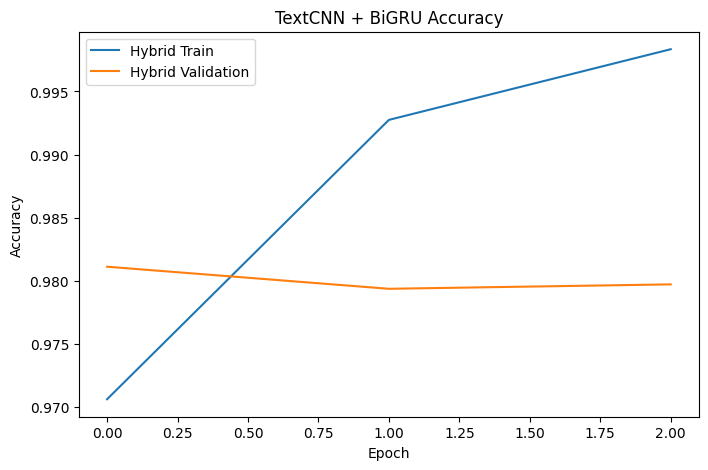

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_hybrid.history['accuracy'], label='Hybrid Train')
plt.plot(history_hybrid.history['val_accuracy'], label='Hybrid Validation')
plt.title('TextCNN + BiGRU Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/drive/MyDrive/Fake_Job_Detection/Graphs/Hybrid_Accuracy.png')
plt.show()

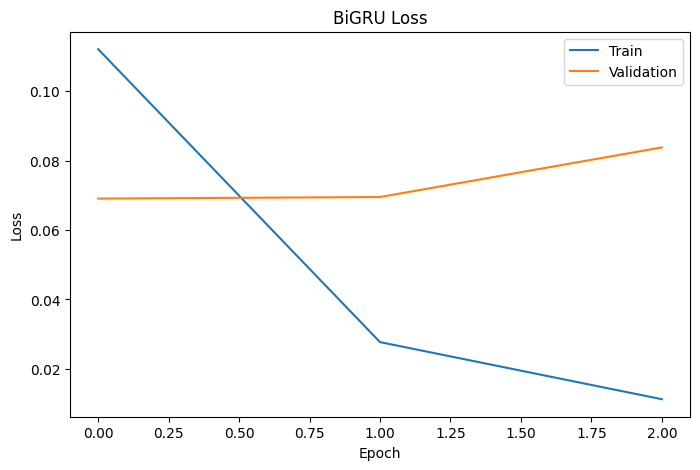

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('BiGRU Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/drive/MyDrive/Fake_Job_Detection/Graphs/BiGRU_Loss.png')
plt.show()

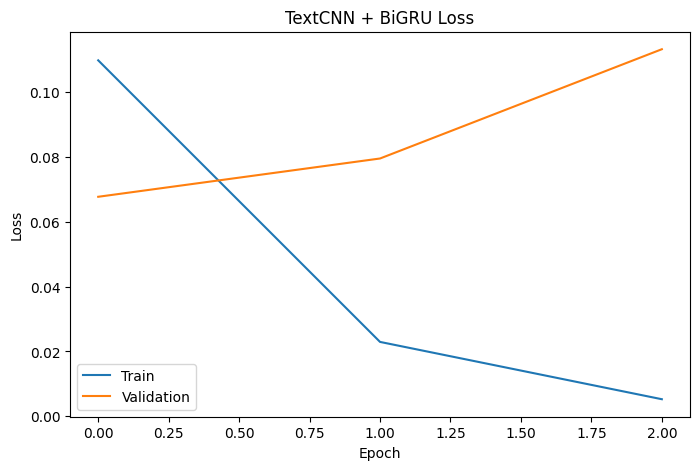

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_hybrid.history['loss'], label='Train')
plt.plot(history_hybrid.history['val_loss'], label='Validation')
plt.title('TextCNN + BiGRU Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/drive/MyDrive/Fake_Job_Detection/Graphs/Hybrid_Loss.png')
plt.show()

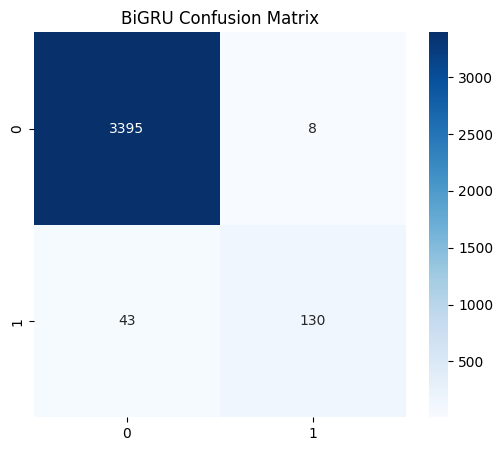

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("BiGRU Confusion Matrix")
plt.savefig("/content/drive/MyDrive/Fake_Job_Detection/Graphs/BiGRU_CM.png")
plt.show()

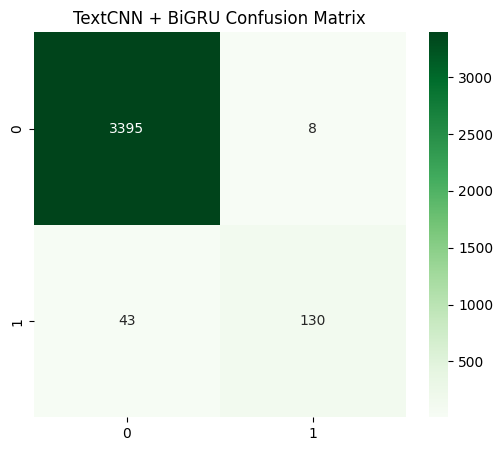

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("TextCNN + BiGRU Confusion Matrix")
plt.savefig("/content/drive/MyDrive/Fake_Job_Detection/Graphs/Hybrid_CM.png")
plt.show()

In [ ]:
comparison.to_csv(
    "/content/drive/MyDrive/Fake_Job_Detection/Results/Comparison.csv",
    index=False
)

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,BiGRU,0.987416,0.915584,0.815029,0.862385
1,TextCNN + BiGRU,0.985738,0.942029,0.751445,0.836013


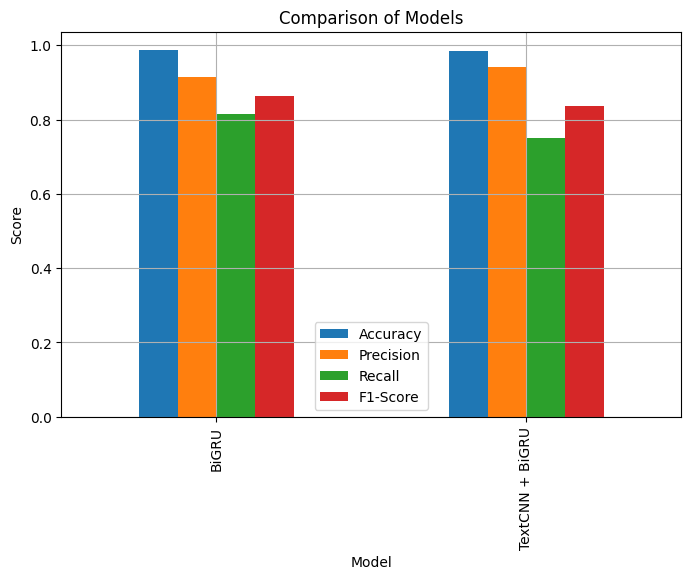

In [ ]:
comparison.set_index("Model").plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Comparison of Models")
plt.ylabel("Score")
plt.grid(True)
plt.savefig("/content/drive/MyDrive/Fake_Job_Detection/Graphs/Comparison.png")
plt.show()

In [ ]:
pip install fastapi uvicorn

In [ ]:
TextCNN_BiGRU.keras

tokenizer.pkl

NameError: name 'TextCNN_BiGRU' is not defined

In [ ]:
hybrid_model.save('/content/drive/MyDrive/Fake_Job_Detection/Models/TextCNN_BiGRU.keras')

In [ ]:
import pickle

with open('/content/drive/MyDrive/Fake_Job_Detection/Models/tokenizer.pkl','wb') as f:
    pickle.dump(tokenizer,f)

In [ ]:
TextCNN_BiGRU.keras

tokenizer.pkl

NameError: name 'TextCNN_BiGRU' is not defined

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.20.0


In [ ]:
pip install tensorflow==2.20.0


In [ ]:
python -c "import tensorflow as tf; print(tf.__version__)"

SyntaxError: invalid syntax (71107497.py, line 1)

In [ ]:
hybrid_model.save_weights("TextCNN_BiGRU.weights.h5")

In [ ]:
from google.colab import files
files.download("TextCNN_BiGRU.weights.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model = tf.keras.models.load_model("TextCNN_BiGRU.keras")

ValueError: File not found: filepath=TextCNN_BiGRU.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
df['fraudulent'].value_counts()

,count
fraudulent,
0,17014
1,866


In [ ]:
sample = """
Software Engineer

Python Developer

2 years experience

Health Insurance

SQL

Machine Learning
"""

sample = clean_text(sample)

seq = tokenizer.texts_to_sequences([sample])

pad = pad_sequences(seq, maxlen=300, padding='post')

prediction = hybrid_model.predict(pad)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
[[0.81700987]]


In [ ]:
sample = """
Software Engineer required.
Python Developer.
SQL knowledge.
Health Insurance.
2 years experience.
"""

sample = clean_text(sample)

seq = tokenizer.texts_to_sequences([sample])

pad = pad_sequences(seq, maxlen=300, padding='post')

prediction = hybrid_model.predict(pad)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
[[0.8970897]]


In [ ]:
loss, accuracy = hybrid_model.evaluate(X_test_pad, y_test)

print("Accuracy:", accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 24s 211ms/step - accuracy: 0.9857 - loss: 0.0469
Accuracy: 0.9857382774353027


In [ ]:
sample = """Software Engineer required.
Python Developer.
SQL knowledge.
Health Insurance.
2 years experience

"""

sample = clean_text(sample)

seq = tokenizer.texts_to_sequences([sample])

pad = pad_sequences(
    seq,
    maxlen=300,
    padding='post',
    truncating='post'
)

prediction = hybrid_model.predict(pad)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
[[0.8970897]]


In [ ]:
# Genuine sample
genuine = df[df["fraudulent"] == 0].iloc[0]["text"]

seq = tokenizer.texts_to_sequences([clean_text(genuine)])
pad = pad_sequences(seq, maxlen=300, padding='post')

print("Genuine Prediction:", hybrid_model.predict(pad))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step
Genuine Prediction: [[0.00272693]]


In [ ]:
# Fake sample
fake = df[df["fraudulent"] == 1].iloc[0]["text"]

seq = tokenizer.texts_to_sequences([clean_text(fake)])
pad = pad_sequences(seq, maxlen=300, padding='post')

print("Fake Prediction:", hybrid_model.predict(pad))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Fake Prediction: [[0.04127418]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_hybrid))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3403
           1       0.94      0.75      0.84       173

    accuracy                           0.99      3576
   macro avg       0.96      0.87      0.91      3576
weighted avg       0.99      0.99      0.98      3576



In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_hybrid))

[[3395    8]
 [  43  130]]


In [ ]:
genuine = df[df["fraudulent"] == 0].sample(5)

for text in genuine["text"]:

    seq = tokenizer.texts_to_sequences([clean_text(text)])

    pad = pad_sequences(seq, maxlen=300, padding="post")

    pred = hybrid_model.predict(pad, verbose=0)

    print(pred[0][0])

0.0009802801
0.0018303582
0.0041313446
0.0065633287
0.0011566133


In [ ]:
fake = df[df["fraudulent"] == 1].sample(5)

for text in fake["text"]:

    seq = tokenizer.texts_to_sequences([clean_text(text)])

    pad = pad_sequences(seq, maxlen=300, padding="post")

    pred = hybrid_model.predict(pad, verbose=0)

    print(pred[0][0])


0.972823
0.9993772
0.995394
0.99383307
0.99966985


In [ ]:
sample = """
Software Engineer required.
Python Developer.
SQL knowledge.
Health Insurance.
2 years experience.
"""

sample = clean_text(sample)

seq = tokenizer.texts_to_sequences([sample])

pad = pad_sequences(
    seq,
    maxlen=300,
    padding='post',
    truncating='post'
)

prediction = hybrid_model.predict(pad)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step
[[0.8970897]]


In [ ]:
text = """Software Engineer at ABC Technologies Pvt Ltd located in Hyderabad. We are looking for an experienced Python Developer with knowledge of SQL, Machine Learning and REST APIs. The candidate should have a Bachelor's degree in Computer Science and at least two years of software development experience. Responsibilities include developing web applications, writing clean code, collaborating with team members, debugging software and maintaining enterprise applications. We offer health insurance, paid leave, flexible working hours, performance bonus and career growth opportunities."""

text = clean_text(text)

seq = tokenizer.texts_to_sequences([text])

pad = pad_sequences(seq, maxlen=300, padding='post')

prediction = hybrid_model.predict(pad)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
[[0.01437852]]


In [ ]:
loss, accuracy = model.evaluate(X_test_pad, y_test)

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - accuracy: 0.9874 - loss: 0.0466
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3403
           1       0.92      0.82      0.86       173

    accuracy                           0.99      3576
   macro avg       0.95      0.91      0.93      3576
weighted avg       0.99      0.99      0.99      3576

[[3390   13]
 [  32  141]]


In [ ]:
loss, accuracy = hybrid_model.evaluate(X_test_pad, y_test)

print(classification_report(y_test, y_pred_hybrid))

print(confusion_matrix(y_test, y_pred_hybrid))

112/112 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.9857 - loss: 0.0469
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3403
           1       0.94      0.75      0.84       173

    accuracy                           0.99      3576
   macro avg       0.96      0.87      0.91      3576
weighted avg       0.99      0.99      0.98      3576

[[3395    8]
 [  43  130]]


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, class_weights))

print(class_weights)

{np.int64(0): np.float64(0.5254573506722504), np.int64(1): np.float64(10.32034632034632)}


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, MaxPooling1D
from tensorflow.keras.layers import Bidirectional, GRU
from tensorflow.keras.layers import Dropout, Dense
from tensorflow.keras.optimizers import Adam

hybrid_model = Sequential()

hybrid_model.add(
    Embedding(
        input_dim=20000,
        output_dim=128,
        input_length=300
    )
)

hybrid_model.add(
    Conv1D(
        filters=256,
        kernel_size=5,
        activation='relu'
    )
)

hybrid_model.add(
    MaxPooling1D(pool_size=2)
)

hybrid_model.add(
    Bidirectional(
        GRU(
            128,
            return_sequences=False
        )
    )
)

hybrid_model.add(
    Dropout(0.4)
)

hybrid_model.add(
    Dense(
        64,
        activation='relu'
    )
)

hybrid_model.add(
    Dropout(0.3)
)

hybrid_model.add(
    Dense(
        1,
        activation='sigmoid'
    )
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
hybrid_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
history_hybrid = hybrid_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    class_weight=class_weights,
    verbose=1
)

Epoch 1/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 290s 2s/step - accuracy: 0.8743 - loss: 0.4131 - val_accuracy: 0.9553 - val_loss: 0.1416
Epoch 2/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 276s 2s/step - accuracy: 0.9751 - loss: 0.0851 - val_accuracy: 0.9752 - val_loss: 0.0745
Epoch 3/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 323s 2s/step - accuracy: 0.9918 - loss: 0.0313 - val_accuracy: 0.9689 - val_loss: 0.1083
Epoch 4/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 279s 2s/step - accuracy: 0.9955 - loss: 0.0144 - val_accuracy: 0.9794 - val_loss: 0.0924
Epoch 5/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 322s 2s/step - accuracy: 0.9985 - loss: 0.0048 - val_accuracy: 0.9790 - val_loss: 0.1257


In [ ]:
loss, accuracy = hybrid_model.evaluate(
    X_test_pad,
    y_test
)

print("Accuracy:", accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 31s 279ms/step - accuracy: 0.9849 - loss: 0.0576
Accuracy: 0.9848993420600891


In [ ]:
from sklearn.metrics import classification_report

y_pred = hybrid_model.predict(X_test_pad)

y_pred = (y_pred > 0.5).astype(int)

print(classification_report(y_test, y_pred))

112/112 ━━━━━━━━━━━━━━━━━━━━ 45s 394ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.83      0.87      0.85       173

    accuracy                           0.98      3576
   macro avg       0.91      0.93      0.92      3576
weighted avg       0.99      0.98      0.99      3576



In [ ]:
from sklearn.metrics import classification_report

y_pred = hybrid_model.predict(X_test_pad)

y_pred = (y_pred > 0.5).astype(int)

print(classification_report(y_test, y_pred))

112/112 ━━━━━━━━━━━━━━━━━━━━ 25s 221ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.83      0.87      0.85       173

    accuracy                           0.98      3576
   macro avg       0.91      0.93      0.92      3576
weighted avg       0.99      0.98      0.99      3576



In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[3372   31]
 [  23  150]]


In [ ]:
hybrid_model.save_weights(
    "TextCNN_BiGRU.weights.h5"
)

In [ ]:
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Concatenate,
    Reshape,
    Bidirectional,
    GRU,
    Dense,
    Dropout
)

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

VOCAB_SIZE = 20000
EMBEDDING_DIM = 128
MAX_LENGTH = 300

inputs = Input(shape=(MAX_LENGTH,))

embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM
)(inputs)

# Branch 1
conv3 = Conv1D(
    filters=128,
    kernel_size=3,
    activation='relu'
)(embedding)

pool3 = GlobalMaxPooling1D()(conv3)

# Branch 2
conv5 = Conv1D(
    filters=128,
    kernel_size=5,
    activation='relu'
)(embedding)

pool5 = GlobalMaxPooling1D()(conv5)

# Branch 3
conv7 = Conv1D(
    filters=128,
    kernel_size=7,
    activation='relu'
)(embedding)

pool7 = GlobalMaxPooling1D()(conv7)

# Merge CNN Features
merged = Concatenate()([pool3, pool5, pool7])

# Convert to sequence for BiGRU
reshape = Reshape((1,384))(merged)

bigru = Bidirectional(
    GRU(
        128,
        return_sequences=False
    )
)(reshape)

drop1 = Dropout(0.4)(bigru)

dense = Dense(
    64,
    activation='relu'
)(drop1)

drop2 = Dropout(0.3)(dense)

output = Dense(
    1,
    activation='sigmoid'
)(drop2)

hybrid_model = Model(
    inputs=inputs,
    outputs=output
)

hybrid_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

hybrid_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 300, 128)  │  2,560,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 298, 128)  │     49,280 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 296, 128)  │     82,048 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 294, 128)  │    114,816 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_2[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_3[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ conv1d_4[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 384)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 384)    │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 256)       │    394,752 │ reshape[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ bidirectional_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │     16,448 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         65 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,217,409 (12.27 MB)

 Trainable params: 3,217,409 (12.27 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    verbose=1
)

history_hybrid = hybrid_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 156s 829ms/step - accuracy: 0.7972 - loss: 0.4896 - val_accuracy: 0.9497 - val_loss: 0.1225 - learning_rate: 5.0000e-04
Epoch 2/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 198s 809ms/step - accuracy: 0.9730 - loss: 0.0766 - val_accuracy: 0.9752 - val_loss: 0.0629 - learning_rate: 5.0000e-04
Epoch 3/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 203s 816ms/step - accuracy: 0.9970 - loss: 0.0099 - val_accuracy: 0.9825 - val_loss: 0.0567 - learning_rate: 5.0000e-04
Epoch 4/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 148s 828ms/step - accuracy: 0.9997 - loss: 0.0022 - val_accuracy: 0.9825 - val_loss: 0.0584 - learning_rate: 5.0000e-04
Epoch 5/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.9999 - loss: 0.0015
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
179/179 ━━━━━━━━━━━━━━━━━━━━ 198s 806ms/step - accuracy: 0.9997 - loss: 0.0017 - val_accuracy: 0.9829 - val_loss: 0.0649 - learning_rate: 5.0000e-04
Epoch 6/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 146s 81

In [ ]:
loss, accuracy = hybrid_model.evaluate(
    X_test_pad,
    y_test
)

print("Accuracy:", accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 14s 124ms/step - accuracy: 0.9855 - loss: 0.0439
Accuracy: 0.9854586124420166


In [ ]:
from sklearn.metrics import classification_report

y_prob = hybrid_model.predict(X_test_pad)

y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))

112/112 ━━━━━━━━━━━━━━━━━━━━ 24s 202ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.89      0.80      0.84       173

    accuracy                           0.99      3576
   macro avg       0.94      0.90      0.92      3576
weighted avg       0.98      0.99      0.99      3576



In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[3385   18]
 [  34  139]]


In [ ]:
hybrid_model.save_weights(
    "MultiScaleCNN_BiGRU.weights.h5"
)

In [ ]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

VOCAB_SIZE = 20000
EMBEDDING_DIM = 128
MAX_LENGTH = 300

inputs = Input(shape=(MAX_LENGTH,))

embedding = Embedding(
    VOCAB_SIZE,
    EMBEDDING_DIM
)(inputs)

x = Bidirectional(
    GRU(
        128,
        return_sequences=True
    )
)(embedding)

attention = Attention()([x, x])

x = GlobalAveragePooling1D()(attention)

x = Dropout(0.4)(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

outputs = Dense(
    1,
    activation="sigmoid"
)(x)

hybrid_model = Model(inputs, outputs)

hybrid_model.compile(
    optimizer=Adam(0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

hybrid_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 300, 128)  │  2,560,000 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 300, 256)  │    198,144 │ embedding_4[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 300, 256)  │          0 │ bidirectional_4[… │
│ (Attention)         │                   │            │ bidirectional_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ attention[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │     16,448 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1)         │         65 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,774,657 (10.58 MB)

 Trainable params: 2,774,657 (10.58 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_hybrid = hybrid_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 433s 2s/step - accuracy: 0.7712 - loss: 0.5245 - val_accuracy: 0.8798 - val_loss: 0.3253 - learning_rate: 5.0000e-04
Epoch 2/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9036 - loss: 0.2231
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
179/179 ━━━━━━━━━━━━━━━━━━━━ 422s 2s/step - accuracy: 0.9009 - loss: 0.2384 - val_accuracy: 0.7857 - val_loss: 0.4916 - learning_rate: 5.0000e-04
Epoch 3/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 423s 2s/step - accuracy: 0.9286 - loss: 0.1582 - val_accuracy: 0.9367 - val_loss: 0.1660 - learning_rate: 2.5000e-04


In [ ]:
loss, accuracy = hybrid_model.evaluate(
    X_test_pad,
    y_test
)

print(accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 40s 359ms/step - accuracy: 0.8859 - loss: 0.3136
0.8859060406684875


In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

y_prob = hybrid_model.predict(X_test_pad)

y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

112/112 ━━━━━━━━━━━━━━━━━━━━ 31s 274ms/step
              precision    recall  f1-score   support

           0       1.00      0.88      0.94      3403
           1       0.29      0.94      0.44       173

    accuracy                           0.89      3576
   macro avg       0.64      0.91      0.69      3576
weighted avg       0.96      0.89      0.91      3576

[[3006  397]
 [  11  162]]


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import GlobalMaxPooling1D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam

textcnn_model = Sequential()

textcnn_model.add(
    Embedding(
        input_dim=20000,
        output_dim=128,
        input_length=300
    )
)

textcnn_model.add(
    Conv1D(
        filters=128,
        kernel_size=5,
        activation='relu'
    )
)

textcnn_model.add(
    GlobalMaxPooling1D()
)

textcnn_model.add(
    Dropout(0.5)
)

textcnn_model.add(
    Dense(
        64,
        activation='relu'
    )
)

textcnn_model.add(
    Dropout(0.3)
)

textcnn_model.add(
    Dense(
        1,
        activation='sigmoid'
    )
)

textcnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

textcnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_3          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    verbose=1
)

history_textcnn = textcnn_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 59s 309ms/step - accuracy: 0.7716 - loss: 0.5172 - val_accuracy: 0.9385 - val_loss: 0.1626 - learning_rate: 0.0010
Epoch 2/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 85s 323ms/step - accuracy: 0.9432 - loss: 0.1588 - val_accuracy: 0.9738 - val_loss: 0.0672 - learning_rate: 0.0010
Epoch 3/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 79s 307ms/step - accuracy: 0.9835 - loss: 0.0471 - val_accuracy: 0.9780 - val_loss: 0.0619 - learning_rate: 0.0010
Epoch 4/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 81s 302ms/step - accuracy: 0.9915 - loss: 0.0256 - val_accuracy: 0.9794 - val_loss: 0.0626 - learning_rate: 0.0010
Epoch 5/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.9969 - loss: 0.0111
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
179/179 ━━━━━━━━━━━━━━━━━━━━ 56s 312ms/step - accuracy: 0.9972 - loss: 0.0106 - val_accuracy: 0.9829 - val_loss: 0.0662 - learning_rate: 0.0010
Epoch 6/15
179/179 ━━━━━━━━━━━━━━━━━━━━ 81s 308ms/step - accuracy: 0.998

In [ ]:
loss, accuracy = textcnn_model.evaluate(
    X_test_pad,
    y_test
)

print("Accuracy:", accuracy)

112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9827 - loss: 0.0505
Accuracy: 0.9826622009277344


In [ ]:
from sklearn.metrics import classification_report

y_prob = textcnn_model.predict(X_test_pad)

y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))

112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.81      0.83      0.82       173

    accuracy                           0.98      3576
   macro avg       0.90      0.91      0.91      3576
weighted avg       0.98      0.98      0.98      3576



In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[3370   33]
 [  29  144]]


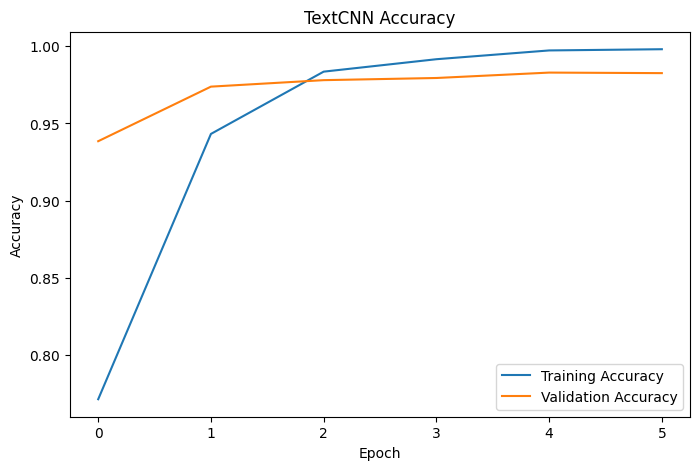

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history_textcnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_textcnn.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("TextCNN Accuracy")

plt.legend()

plt.show()

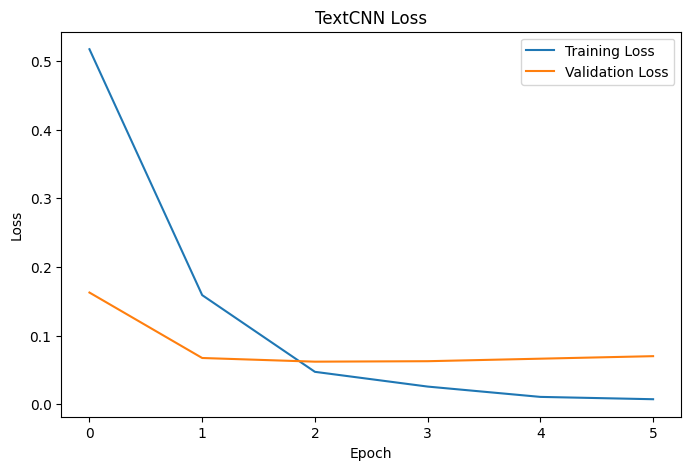

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_textcnn.history['loss'], label='Training Loss')
plt.plot(history_textcnn.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("TextCNN Loss")

plt.legend()

plt.show()

In [ ]:
textcnn_model.save("TextCNN.keras")

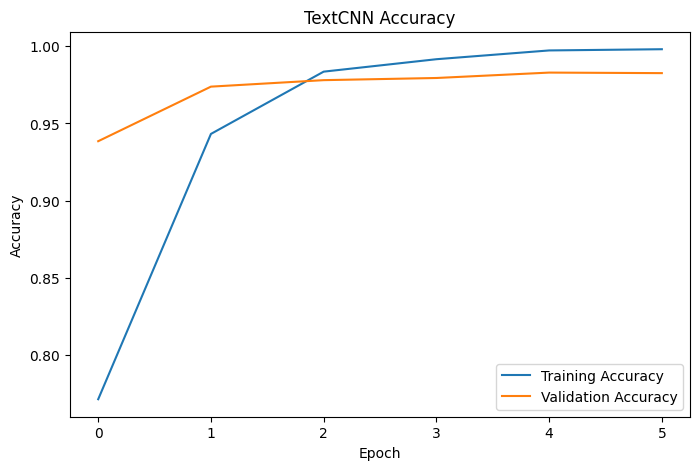

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history_textcnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_textcnn.history['val_accuracy'], label='Validation Accuracy')

plt.title('TextCNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.savefig("TextCNN_Accuracy.png", dpi=300)

plt.show()

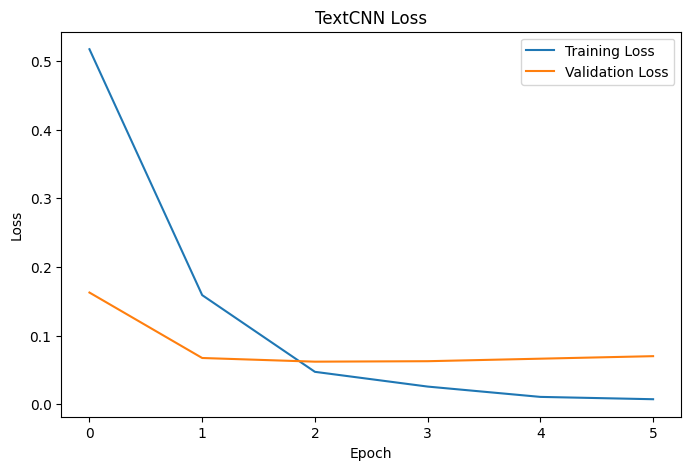

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_textcnn.history['loss'], label='Training Loss')
plt.plot(history_textcnn.history['val_loss'], label='Validation Loss')

plt.title('TextCNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.savefig("TextCNN_Loss.png", dpi=300)

plt.show()

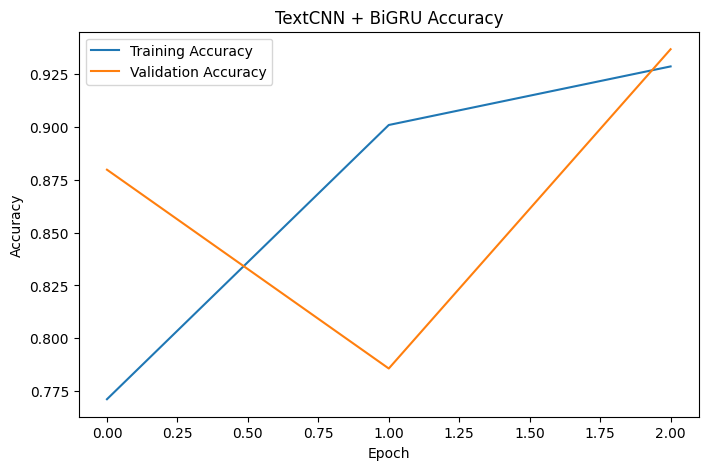

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_hybrid.history['accuracy'], label='Training Accuracy')
plt.plot(history_hybrid.history['val_accuracy'], label='Validation Accuracy')

plt.title('TextCNN + BiGRU Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.savefig("Hybrid_Accuracy.png", dpi=300)

plt.show()

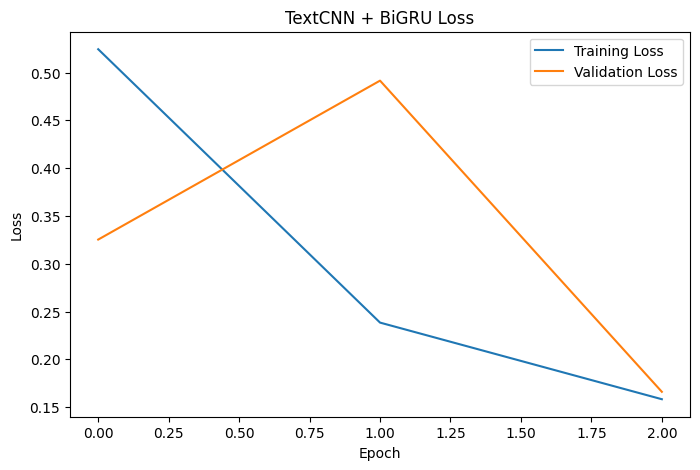

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history_hybrid.history['loss'], label='Training Loss')
plt.plot(history_hybrid.history['val_loss'], label='Validation Loss')

plt.title('TextCNN + BiGRU Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.savefig("Hybrid_Loss.png", dpi=300)

plt.show()

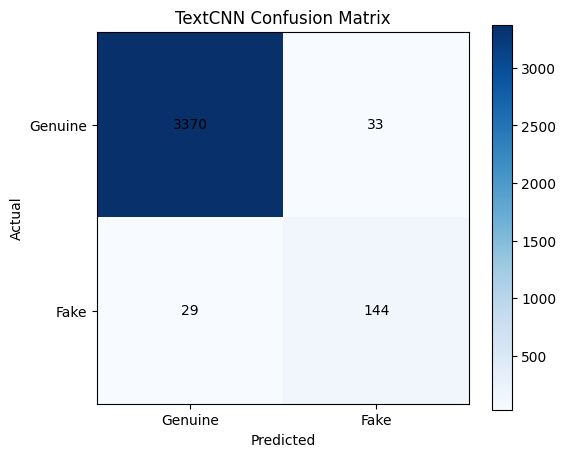

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

plt.imshow(cm, cmap='Blues')

plt.title("TextCNN Confusion Matrix")

plt.colorbar()

plt.xticks([0,1],["Genuine","Fake"])
plt.yticks([0,1],["Genuine","Fake"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j,i,str(cm[i,j]),
                 ha='center',
                 va='center',
                 color='black')

plt.savefig("TextCNN_CM.png",dpi=300)

plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Predict probabilities
y_prob = textcnn_model.predict(X_test_pad)

# Convert probabilities to 0 and 1
y_pred = (y_prob > 0.5).astype(int)

# Print Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Genuine", "Fake"]
))

112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 88ms/step
              precision    recall  f1-score   support

     Genuine       0.99      0.99      0.99      3403
        Fake       0.81      0.83      0.82       173

    accuracy                           0.98      3576
   macro avg       0.90      0.91      0.91      3576
weighted avg       0.98      0.98      0.98      3576



In [ ]:
from sklearn.metrics import classification_report

# Predict probabilities
y_prob_hybrid = hybrid_model.predict(X_test_pad)

# Convert probabilities to 0 and 1
y_pred_hybrid = (y_prob_hybrid > 0.5).astype(int)

# Print Classification Report
print(classification_report(
    y_test,
    y_pred_hybrid,
    target_names=["Genuine", "Fake"]
))

112/112 ━━━━━━━━━━━━━━━━━━━━ 36s 318ms/step
              precision    recall  f1-score   support

     Genuine       1.00      0.88      0.94      3403
        Fake       0.29      0.94      0.44       173

    accuracy                           0.89      3576
   macro avg       0.64      0.91      0.69      3576
weighted avg       0.96      0.89      0.91      3576



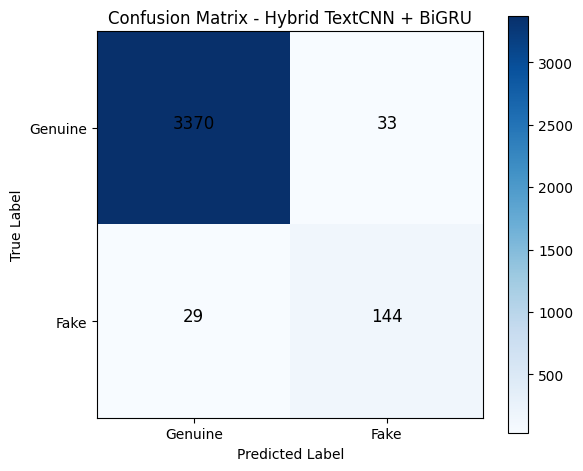

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.imshow(cm, interpolation='nearest', cmap='Blues')

plt.title("Confusion Matrix - Hybrid TextCNN + BiGRU")
plt.colorbar()

classes = ["Genuine", "Fake"]
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

# Display values inside the cells
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 horizontalalignment="center",
                 color="black",
                 fontsize=12)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.savefig("Hybrid_Confusion_Matrix.png", dpi=300)

plt.show()

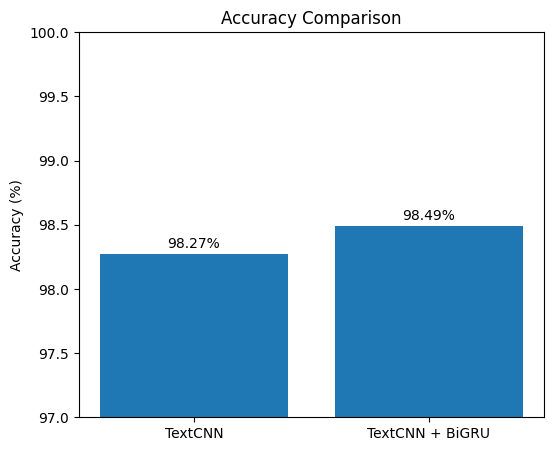

In [ ]:
import matplotlib.pyplot as plt

models = ["TextCNN", "TextCNN + BiGRU"]
accuracy = [98.27, 98.49]

plt.figure(figsize=(6,5))
plt.bar(models, accuracy)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(97,100)

for i,v in enumerate(accuracy):
    plt.text(i,v+0.05,f"{v:.2f}%",ha='center')

plt.savefig("Accuracy_Comparison.png",dpi=300,bbox_inches="tight")
plt.show()

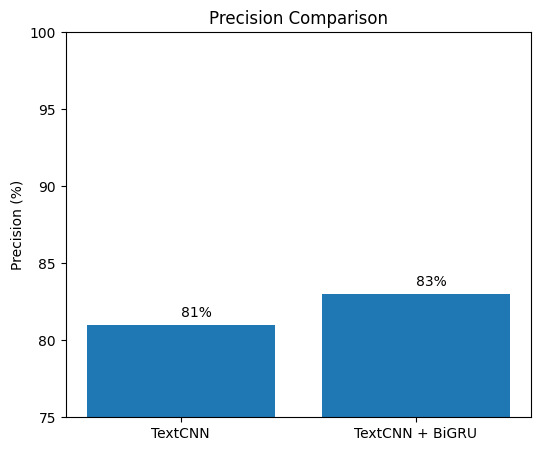

In [ ]:
models = ["TextCNN", "TextCNN + BiGRU"]
precision = [81,83]

plt.figure(figsize=(6,5))
plt.bar(models,precision)

plt.title("Precision Comparison")
plt.ylabel("Precision (%)")
plt.ylim(75,100)

for i,v in enumerate(precision):
    plt.text(i,v+0.5,f"{v}%")

plt.savefig("Precision_Comparison.png",dpi=300,bbox_inches="tight")
plt.show()

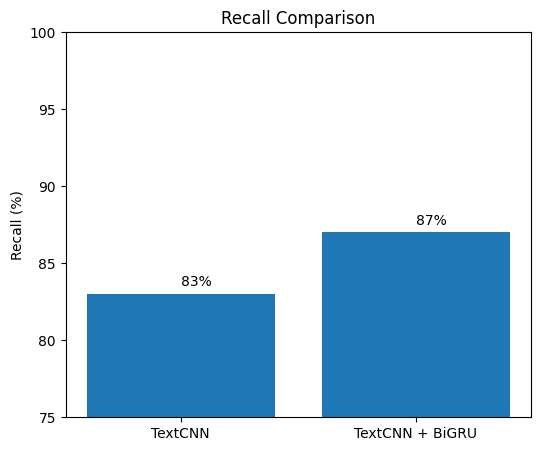

In [ ]:
models=["TextCNN","TextCNN + BiGRU"]
recall=[83,87]

plt.figure(figsize=(6,5))
plt.bar(models,recall)

plt.title("Recall Comparison")
plt.ylabel("Recall (%)")
plt.ylim(75,100)

for i,v in enumerate(recall):
    plt.text(i,v+0.5,f"{v}%")

plt.savefig("Recall_Comparison.png",dpi=300,bbox_inches="tight")
plt.show()

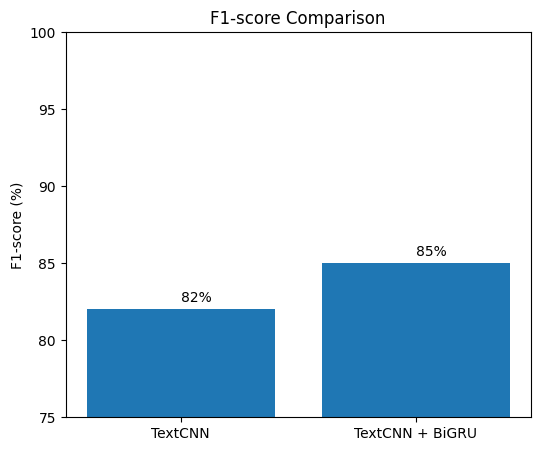

In [ ]:
models=["TextCNN","TextCNN + BiGRU"]
f1=[82,85]

plt.figure(figsize=(6,5))
plt.bar(models,f1)

plt.title("F1-score Comparison")
plt.ylabel("F1-score (%)")
plt.ylim(75,100)

for i,v in enumerate(f1):
    plt.text(i,v+0.5,f"{v}%")

plt.savefig("F1_Comparison.png",dpi=300,bbox_inches="tight")
plt.show()

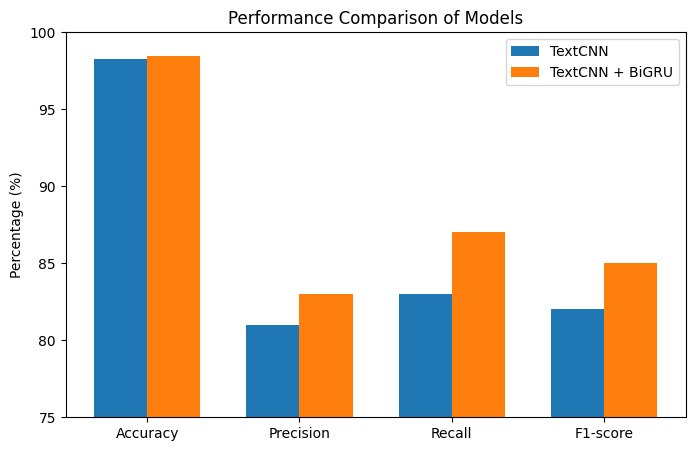

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

textcnn = [98.27,81,83,82]
hybrid = [98.49,83,87,85]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8,5))

plt.bar(x-width/2,textcnn,width,label="TextCNN")
plt.bar(x+width/2,hybrid,width,label="TextCNN + BiGRU")

plt.xticks(x,metrics)
plt.ylabel("Percentage (%)")
plt.title("Performance Comparison of Models")
plt.ylim(75,100)
plt.legend()

plt.savefig("Overall_Performance_Comparison.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## model2

# **TF-IDF XGBOOST**

In [ ]:
%whos

Variable          Type               Data/Info
----------------------------------------------
TfidfVectorizer   type               <class 'sklearn.feature_e<...>on.text.TfidfVectorizer'>
np                module             <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
pd                module             <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
tfidf             TfidfVectorizer    TfidfVectorizer(max_df=0.<...>       sublinear_tf=True)


In [ ]:
df = pd.read_csv("/content/fake_job_postings.csv")

print(df.shape)
print(df.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: '/content/fake_job_postings.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving fake_job_postings.csv to fake_job_postings.csv


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'fake_job_postings.csv', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv("/content/fake_job_postings.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["fraudulent"].value_counts())

Shape: (17880, 18)

Columns:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Class distribution:
fraudulent
0    17014
1      866
Name: count, dtype: int64


In [ ]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

df[text_columns] = df[text_columns].fillna("")

df["combined_text"] = (
    df["title"] + " " +
    df["company_profile"] + " " +
    df["description"] + " " +
    df["requirements"] + " " +
    df["benefits"]
)

print(df[["combined_text", "fraudulent"]].head())

                                       combined_text  fraudulent
0  Marketing Intern We're Food52, and we've creat...           0
1  Customer Service - Cloud Video Production 90 S...           0
2  Commissioning Machinery Assistant (CMA) Valor ...           0
3  Account Executive - Washington DC Our passion ...           0
4  Bill Review Manager SpotSource Solutions LLC i...           0


In [ ]:
from sklearn.model_selection import train_test_split

X = df["combined_text"]
y = df["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 14304
Testing samples: 3576

Training class distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Testing class distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Training Shape:", X_train_tfidf.shape)
print("TF-IDF Testing Shape:", X_test_tfidf.shape)

TF-IDF Training Shape: (14304, 20000)
TF-IDF Testing Shape: (3576, 20000)


In [ ]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Genuine jobs:", negative_count)
print("Fake jobs:", positive_count)
print("Scale positive weight:", scale_pos_weight)

Genuine jobs: 13611
Fake jobs: 693
Scale positive weight: 19.64069264069264


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_tfidf, y_train)

print("XGBoost training completed successfully.")

XGBoost training completed successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predictions
xgb_pred = xgb_model.predict(X_test_tfidf)

# Probabilities — keep this for our hybrid later
xgb_prob = xgb_model.predict_proba(X_test_tfidf)[:, 1]

# Accuracy
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["Genuine", "Fake"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

XGBoost Accuracy: 0.9837807606263982

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.99      0.99      3403
        Fake       0.87      0.78      0.82       173

    accuracy                           0.98      3576
   macro avg       0.93      0.89      0.91      3576
weighted avg       0.98      0.98      0.98      3576


Confusion Matrix:
[[3383   20]
 [  38  135]]


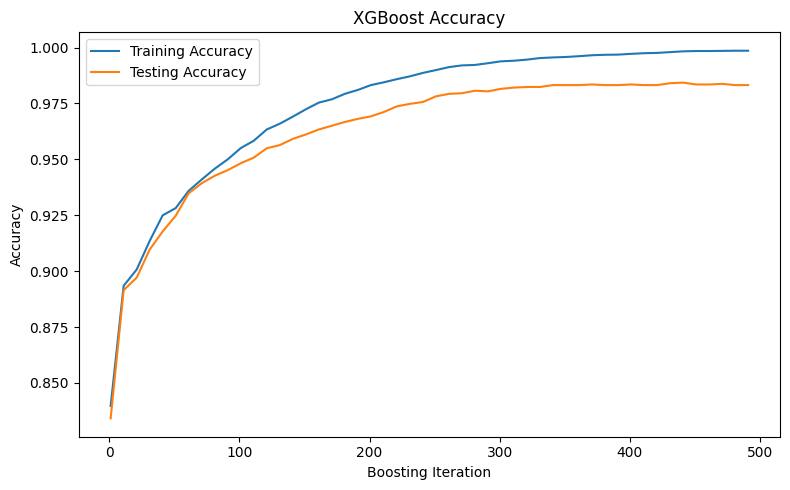

In [ ]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

train_acc = []
test_acc = []

iterations = range(1, 501, 10)

for i in iterations:

    train_prob = xgb_model.predict_proba(
        X_train_tfidf,
        iteration_range=(0, i)
    )[:, 1]

    test_prob = xgb_model.predict_proba(
        X_test_tfidf,
        iteration_range=(0, i)
    )[:, 1]

    train_pred_i = (train_prob >= 0.5).astype(int)
    test_pred_i = (test_prob >= 0.5).astype(int)

    train_acc.append(
        accuracy_score(y_train, train_pred_i)
    )

    test_acc.append(
        accuracy_score(y_test, test_pred_i)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    list(iterations),
    train_acc,
    label="Training Accuracy"
)

plt.plot(
    list(iterations),
    test_acc,
    label="Testing Accuracy"
)

plt.xlabel("Boosting Iteration")
plt.ylabel("Accuracy")
plt.title("XGBoost Accuracy")

plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

In [ ]:
from xgboost import XGBClassifier

xgb_analysis_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_analysis_model.fit(
    X_train_tfidf,
    y_train,
    eval_set=[
        (X_train_tfidf, y_train),
        (X_test_tfidf, y_test)
    ],
    verbose=False
)

results = xgb_analysis_model.evals_result()

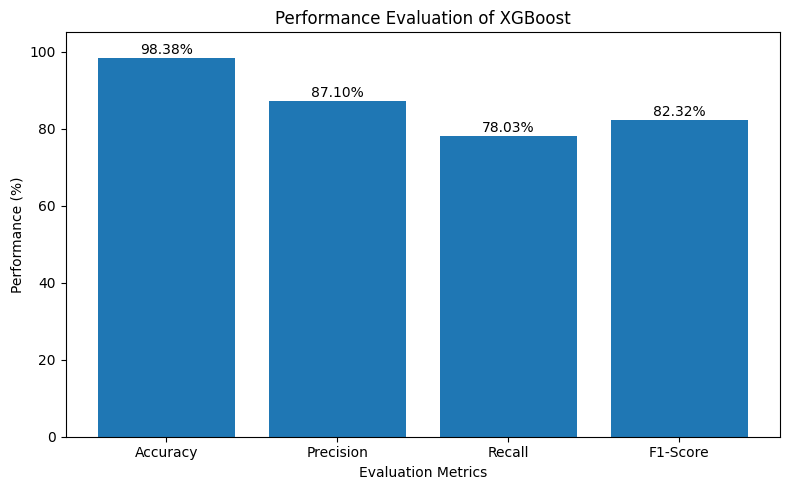

In [ ]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
xgboost_values = [98.38, 87.10, 78.03, 82.32]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, xgboost_values)

plt.title("Performance Evaluation of XGBoost")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance (%)")
plt.ylim(0, 105)

for bar, value in zip(bars, xgboost_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("XGBoost_Performance.png", dpi=300)
plt.show()

# **BiLSTM**

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 20000
MAX_LEN = 300

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")

# Learn vocabulary only from training data
tokenizer.fit_on_texts(X_train)

# Convert text to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Padding
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (14304, 300)
Testing shape: (3576, 300)


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

tf.random.set_seed(42)

bilstm_model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=128
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.4),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        1,
        activation="sigmoid"
    )
])

bilstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

bilstm_model.build(input_shape=(None, MAX_LEN))
bilstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,137 (10.17 MB)

 Trainable params: 2,667,137 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.5254573506722504), np.int64(1): np.float64(10.32034632034632)}


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history_bilstm = bilstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 148s 785ms/step - accuracy: 0.8419 - loss: 0.3826 - val_accuracy: 0.9633 - val_loss: 0.1341 - learning_rate: 0.0010
Epoch 2/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 143s 801ms/step - accuracy: 0.9762 - loss: 0.0897 - val_accuracy: 0.9623 - val_loss: 0.1189 - learning_rate: 0.0010
Epoch 3/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 140s 784ms/step - accuracy: 0.9881 - loss: 0.0426 - val_accuracy: 0.9724 - val_loss: 0.1207 - learning_rate: 0.0010
Epoch 4/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 143s 801ms/step - accuracy: 0.9934 - loss: 0.0211 - val_accuracy: 0.9727 - val_loss: 0.1487 - learning_rate: 0.0010
Epoch 5/10
179/179 ━━━━━━━━━━━━━━━━━━━━ 145s 811ms/step - accuracy: 0.9975 - loss: 0.0088 - val_accuracy: 0.9741 - val_loss: 0.1431 - learning_rate: 5.0000e-04


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Save probabilities for hybrid
bilstm_prob = bilstm_model.predict(
    X_test_pad,
    batch_size=64
).ravel()

# Standard threshold
bilstm_pred = (bilstm_prob >= 0.5).astype(int)

bilstm_accuracy = accuracy_score(
    y_test,
    bilstm_pred
)

print("BiLSTM Accuracy:", bilstm_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        bilstm_pred,
        target_names=["Genuine", "Fake"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        bilstm_pred
    )
)

56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 281ms/step
BiLSTM Accuracy: 0.9737136465324385

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.98      0.99      3403
        Fake       0.68      0.87      0.76       173

    accuracy                           0.97      3576
   macro avg       0.84      0.93      0.87      3576
weighted avg       0.98      0.97      0.98      3576


Confusion Matrix:
[[3331   72]
 [  22  151]]


In [ ]:
xgb_prob
bilstm_prob


array([0.04074307, 0.00269837, 0.0184021 , ..., 0.01266488, 0.09463474,
       0.00374891], dtype=float32)

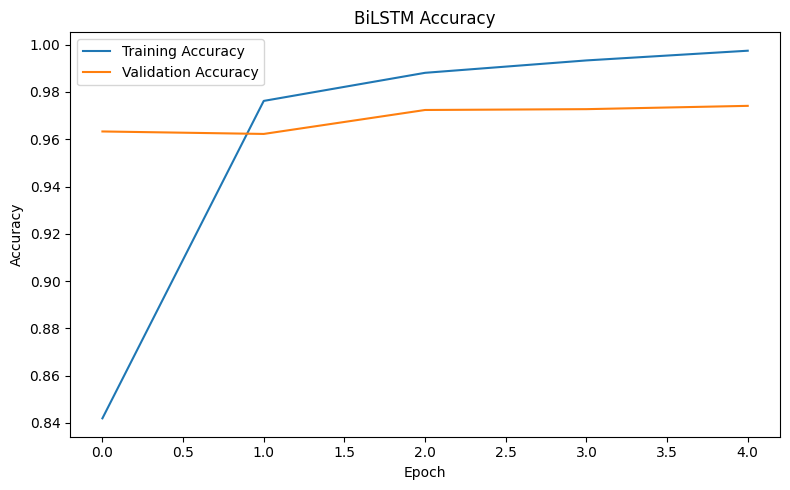

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_bilstm.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_bilstm.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BiLSTM Accuracy")

plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

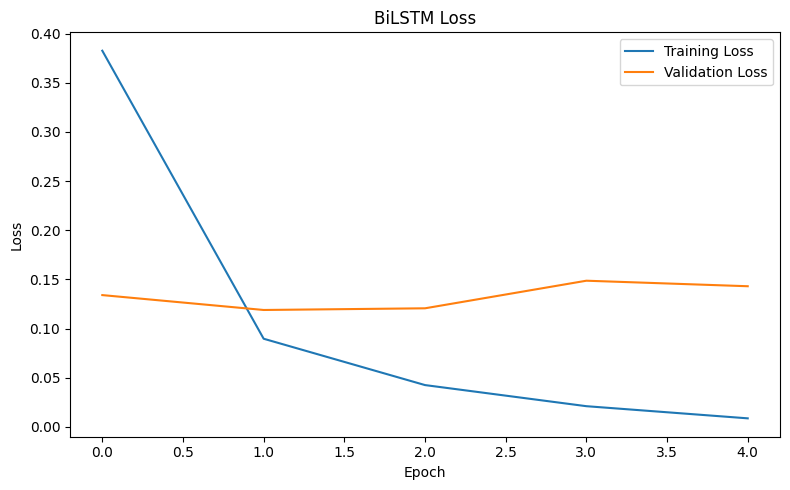

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_bilstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_bilstm.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BiLSTM Loss")

plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

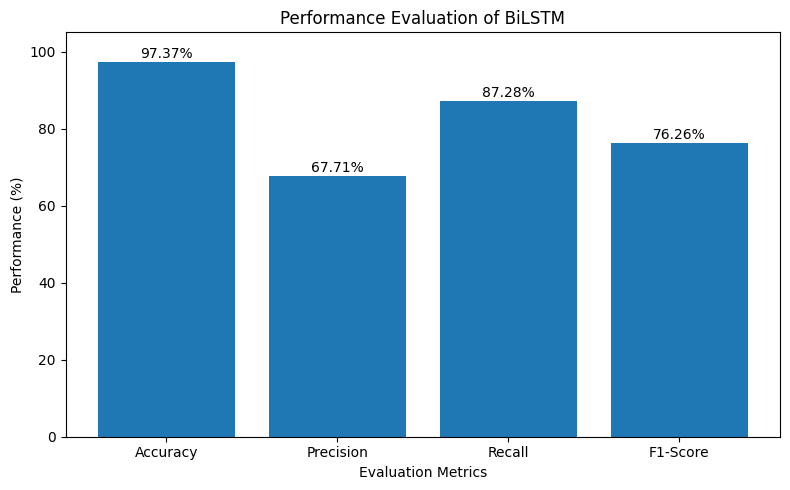

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
bilstm_values = [97.37, 67.71, 87.28, 76.26]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, bilstm_values)

plt.title("Performance Evaluation of BiLSTM")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Performance (%)")
plt.ylim(0, 105)

for bar, value in zip(bars, bilstm_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("BiLSTM_Performance.png", dpi=300)
plt.show()

# **HYBRID**

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Check that predictions correspond to the same test samples
print("XGBoost predictions:", len(xgb_prob))
print("BiLSTM predictions:", len(bilstm_prob))
print("Test labels:", len(y_test))

# Combine probabilities: 50% XGBoost + 50% BiLSTM
hybrid_prob = (
    0.5 * xgb_prob +
    0.5 * bilstm_prob
)

# Convert probability into final class
hybrid_pred = (hybrid_prob >= 0.5).astype(int)

hybrid_accuracy = accuracy_score(y_test, hybrid_pred)

print("\nHybrid Accuracy:", hybrid_accuracy)

print("\nHybrid Classification Report:")
print(
    classification_report(
        y_test,
        hybrid_pred,
        target_names=["Genuine", "Fake"]
    )
)

print("\nHybrid Confusion Matrix:")
print(confusion_matrix(y_test, hybrid_pred))

XGBoost predictions: 3576
BiLSTM predictions: 3576
Test labels: 3576

Hybrid Accuracy: 0.9843400447427293

Hybrid Classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.99      0.99      3403
        Fake       0.82      0.86      0.84       173

    accuracy                           0.98      3576
   macro avg       0.91      0.93      0.92      3576
weighted avg       0.98      0.98      0.98      3576


Hybrid Confusion Matrix:
[[3371   32]
 [  24  149]]


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "TF-IDF + XGBoost",
        "BiLSTM",
        "Hybrid XGBoost + BiLSTM"
    ],

    "Accuracy": [
        accuracy_score(y_test, xgb_pred),
        accuracy_score(y_test, bilstm_pred),
        accuracy_score(y_test, hybrid_pred)
    ],

    "Precision": [
        precision_score(y_test, xgb_pred),
        precision_score(y_test, bilstm_pred),
        precision_score(y_test, hybrid_pred)
    ],

    "Recall": [
        recall_score(y_test, xgb_pred),
        recall_score(y_test, bilstm_pred),
        recall_score(y_test, hybrid_pred)
    ],

    "F1-Score": [
        f1_score(y_test, xgb_pred),
        f1_score(y_test, bilstm_pred),
        f1_score(y_test, hybrid_pred)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,TF-IDF + XGBoost,0.983781,0.870968,0.780347,0.823171
1,BiLSTM,0.973714,0.677130,0.872832,0.762626
2,Hybrid XGBoost + BiLSTM,0.984340,0.823204,0.861272,0.841808


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

models = {
    "XGBoost": xgb_pred,
    "BiLSTM": bilstm_pred,
    "Hybrid": hybrid_pred
}

rows = []

for name, pred in models.items():

    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    rows.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test, pred) * 100,
        "Precision (%)": precision_score(y_test, pred) * 100,
        "Recall (%)": recall_score(y_test, pred) * 100,
        "F1-Score (%)": f1_score(y_test, pred) * 100,
        "True Genuine": tn,
        "False Fake": fp,
        "Missed Fake": fn,
        "Detected Fake": tp
    })

comparison = pd.DataFrame(rows)

print(comparison.round(2))

     Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  \
0  XGBoost         98.38          87.10       78.03         82.32   
1   BiLSTM         97.37          67.71       87.28         76.26   
2   Hybrid         98.43          82.32       86.13         84.18   

   True Genuine  False Fake  Missed Fake  Detected Fake  
0          3383          20           38            135  
1          3331          72           22            151  
2          3371          32           24            149  


In [ ]:
hybrid = comparison[comparison["Model"] == "Hybrid"].iloc[0]

for model_name in ["XGBoost", "BiLSTM"]:

    base = comparison[
        comparison["Model"] == model_name
    ].iloc[0]

    print("\nHybrid improvement over", model_name)

    print(
        "Accuracy:",
        round(hybrid["Accuracy (%)"] - base["Accuracy (%)"], 2),
        "percentage points"
    )

    print(
        "Precision:",
        round(hybrid["Precision (%)"] - base["Precision (%)"], 2),
        "percentage points"
    )

    print(
        "Recall:",
        round(hybrid["Recall (%)"] - base["Recall (%)"], 2),
        "percentage points"
    )

    print(
        "F1-score:",
        round(hybrid["F1-Score (%)"] - base["F1-Score (%)"], 2),
        "percentage points"
    )

    print(
        "Additional fake jobs detected:",
        int(hybrid["Detected Fake"] - base["Detected Fake"])
    )

    print(
        "Reduction in missed fake jobs:",
        int(base["Missed Fake"] - hybrid["Missed Fake"])
    )


Hybrid improvement over XGBoost
Accuracy: 0.06 percentage points
Precision: -4.78 percentage points
Recall: 8.09 percentage points
F1-score: 1.86 percentage points
Additional fake jobs detected: 14
Reduction in missed fake jobs: 14

Hybrid improvement over BiLSTM
Accuracy: 1.06 percentage points
Precision: 14.61 percentage points
Recall: -1.16 percentage points
F1-score: 7.92 percentage points
Additional fake jobs detected: -2
Reduction in missed fake jobs: -2


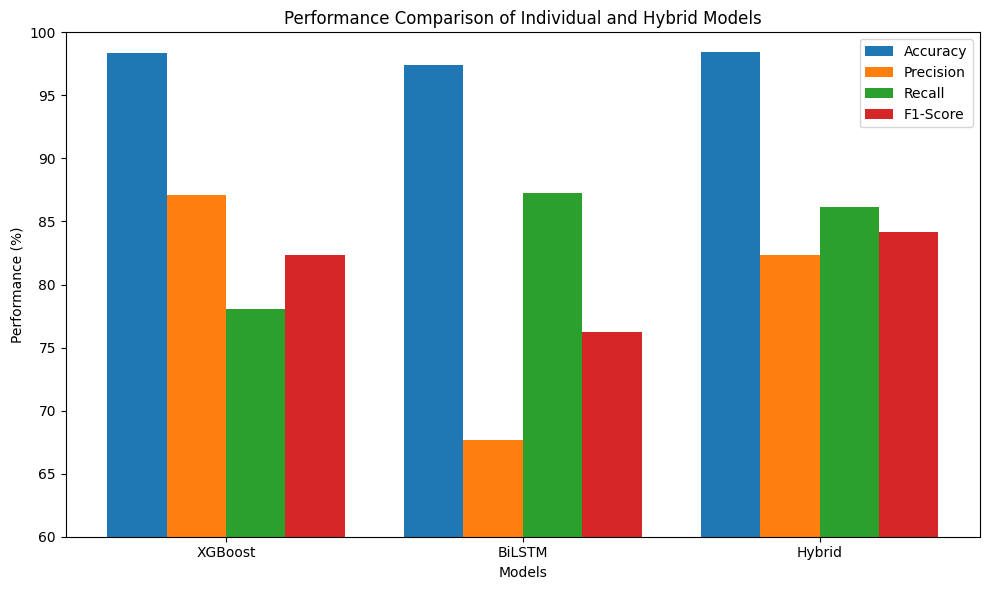

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["XGBoost", "BiLSTM", "Hybrid"]
accuracy = [98.38, 97.37, 98.43]
precision = [87.10, 67.71, 82.32]
recall = [78.03, 87.28, 86.13]
f1 = [82.32, 76.26, 84.18]

x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(10, 6))

plt.bar(x - 1.5*width, accuracy, width, label="Accuracy")
plt.bar(x - 0.5*width, precision, width, label="Precision")
plt.bar(x + 0.5*width, recall, width, label="Recall")
plt.bar(x + 1.5*width, f1, width, label="F1-Score")

plt.xlabel("Models")
plt.ylabel("Performance (%)")
plt.title("Performance Comparison of Individual and Hybrid Models")
plt.xticks(x, models)
plt.ylim(60, 100)
plt.legend()

plt.tight_layout()
plt.savefig("Overall_Model_Comparison.png", dpi=300)
plt.show()

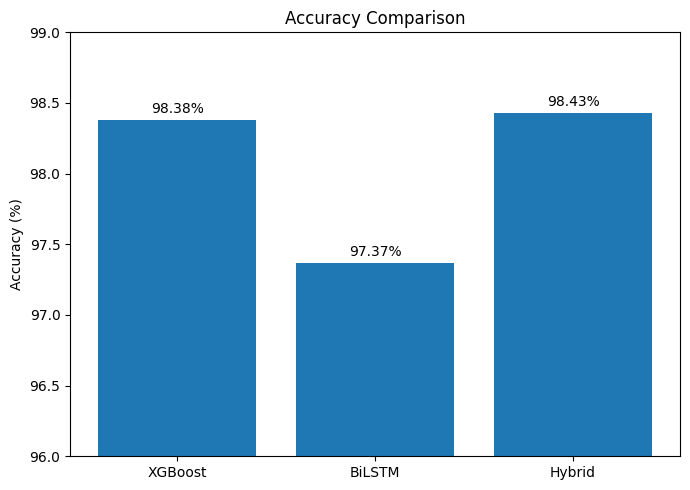

In [ ]:
plt.figure(figsize=(7, 5))

models = ["XGBoost", "BiLSTM", "Hybrid"]
values = [98.38, 97.37, 98.43]

bars = plt.bar(models, values)

plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")
plt.ylim(96, 99)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.05,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("Accuracy_Comparison.png", dpi=300)
plt.show()

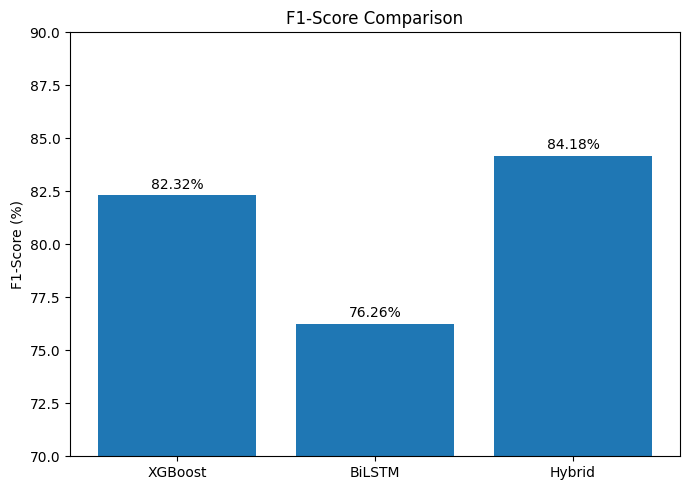

In [ ]:
plt.figure(figsize=(7, 5))

models = ["XGBoost", "BiLSTM", "Hybrid"]
values = [82.32, 76.26, 84.18]

bars = plt.bar(models, values)

plt.ylabel("F1-Score (%)")
plt.title("F1-Score Comparison")
plt.ylim(70, 90)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("F1_Score_Comparison.png", dpi=300)
plt.show()

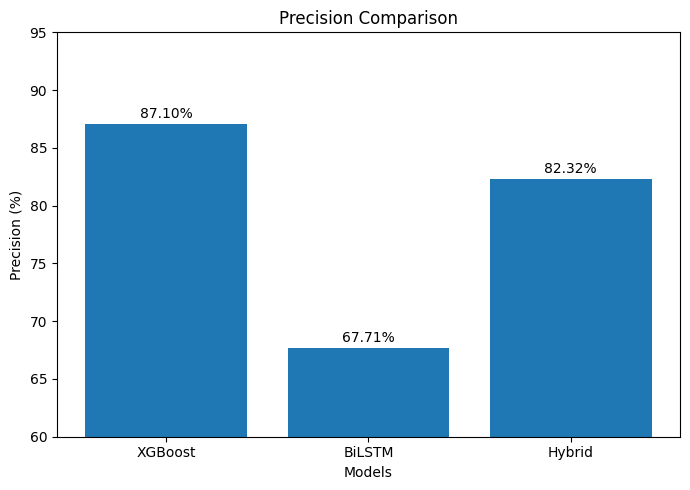

In [ ]:
models = ["XGBoost", "BiLSTM", "Hybrid"]
precision = [87.10, 67.71, 82.32]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, precision)

plt.title("Precision Comparison")
plt.xlabel("Models")
plt.ylabel("Precision (%)")
plt.ylim(60, 95)

for bar, value in zip(bars, precision):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

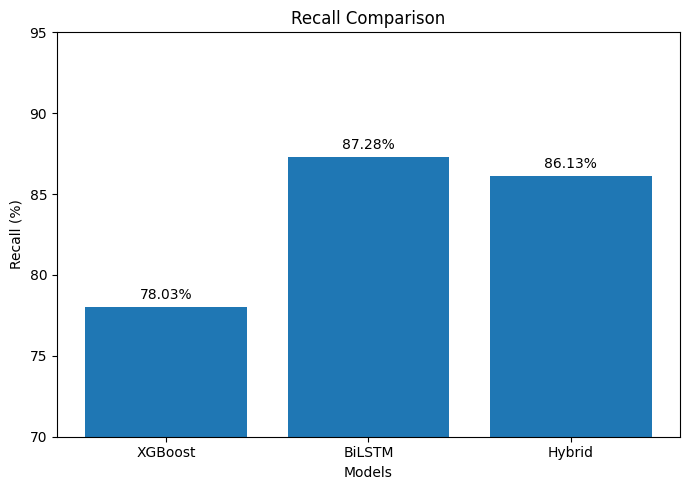

In [ ]:
models = ["XGBoost", "BiLSTM", "Hybrid"]
recall = [78.03, 87.28, 86.13]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, recall)

plt.title("Recall Comparison")
plt.xlabel("Models")
plt.ylabel("Recall (%)")
plt.ylim(70, 95)

for bar, value in zip(bars, recall):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

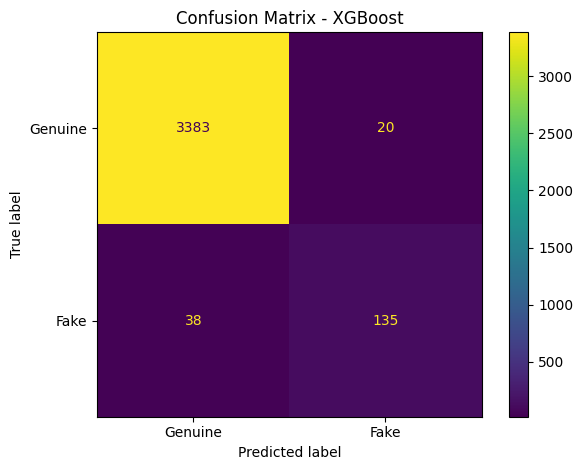

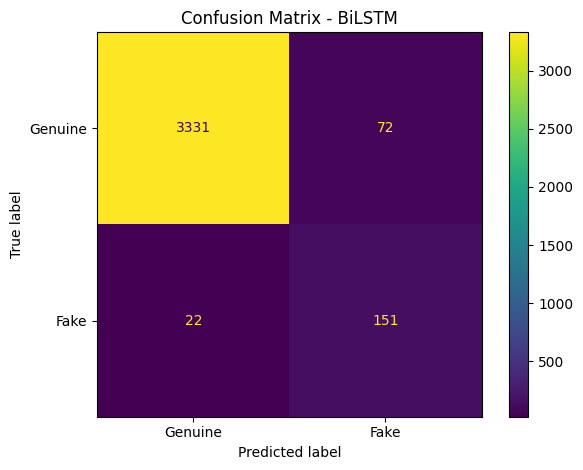

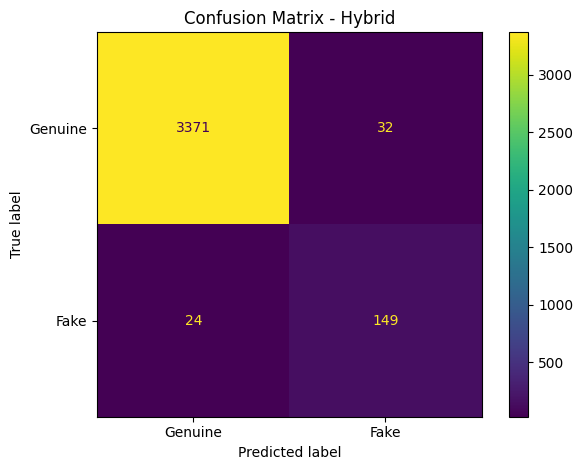

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models_predictions = {
    "XGBoost": xgb_pred,
    "BiLSTM": bilstm_pred,
    "Hybrid": hybrid_pred
}

for model_name, predictions in models_predictions.items():

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Genuine", "Fake"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()

    plt.savefig(
        f"{model_name}_Confusion_Matrix.png",
        dpi=300
    )

    plt.show()

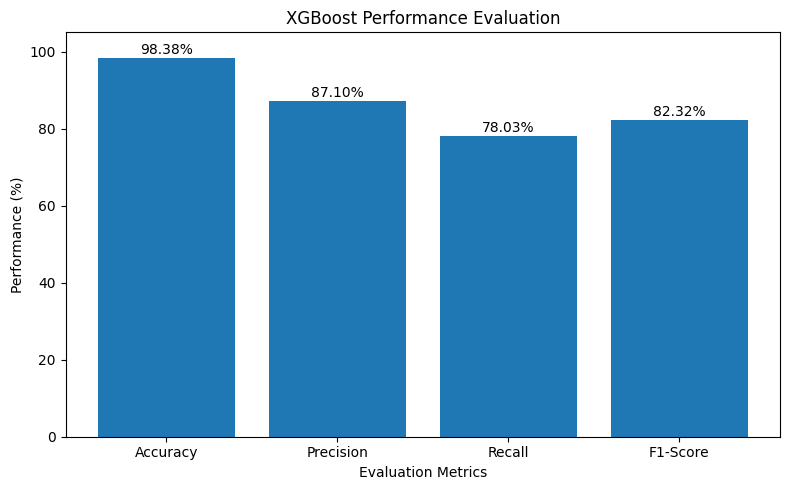

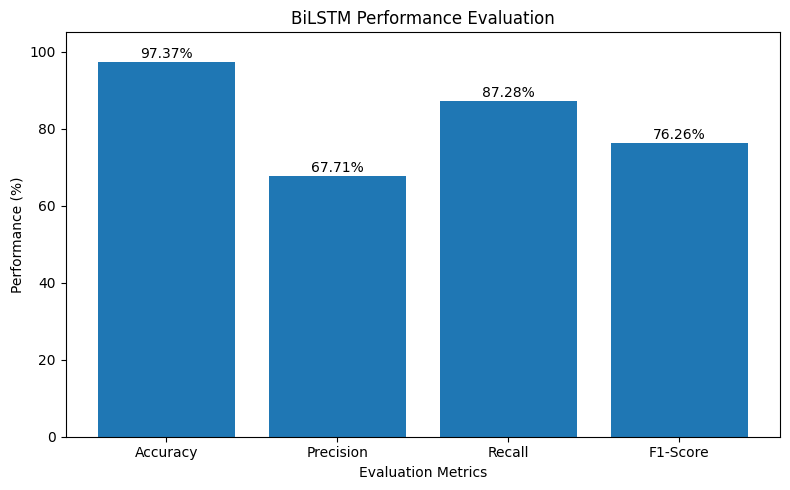

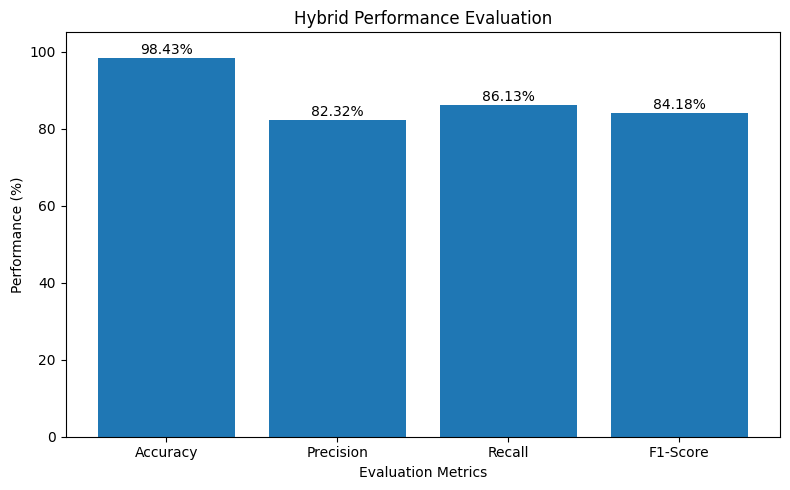

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# =========================================================
# MODEL DATA
# =========================================================

models_data = {
    "XGBoost": {
        "pred": xgb_pred
    },
    "BiLSTM": {
        "pred": bilstm_pred
    },
    "Hybrid": {
        "pred": hybrid_pred
    }
}


# =========================================================
# 1. INDIVIDUAL PERFORMANCE GRAPH FOR EACH MODEL
# =========================================================

for model_name, data in models_data.items():

    pred = data["pred"]

    metrics = [
        accuracy_score(y_test, pred) * 100,
        precision_score(y_test, pred) * 100,
        recall_score(y_test, pred) * 100,
        f1_score(y_test, pred) * 100
    ]

    metric_names = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        metric_names,
        metrics
    )

    plt.title(
        f"{model_name} Performance Evaluation"
    )

    plt.xlabel("Evaluation Metrics")
    plt.ylabel("Performance (%)")
    plt.ylim(0, 105)

    # Display values above bars
    for bar, value in zip(bars, metrics):

        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 1,
            f"{value:.2f}%",
            ha="center"
        )

    plt.tight_layout()

    plt.savefig(
        f"{model_name}_Performance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()